# 🏏 IPL Data Analysis


## 📁 Dataset Information

**Key Columns:**
- `id:` A unique identifier assigned to each IPL match.
- `season:` The year in which the IPL season took place.
- `city`: The city where the match was played.
- `date`: The date on which the match was held.
- `match_type`: Type of the match (e.g., League, Playoff, Final).
- `player_of_match`: The player who was awarded “Player of the Match” for their performance.
- `venue`: The stadium or ground where the match was played.
- `team1`: The first team listed in the fixture.
- `team2`: The second team listed in the fixture.
- `toss_winner`: The team that won the toss before the match began.
- `toss_decision`: The decision made by the toss-winning team—either to bat or to field first.
- `winner`: The team that won the match.
- `result`: The method of victory—either by runs, wickets, or other (e.g., tie, no result).
- `result_margin`: The margin by which the match was won (e.g., number of runs or wickets).
- `target_runs`: The number of runs set as a target for the chasing team.
- `target_overs`: The number of overs available to chase the target.
- `super_over`: Indicates whether the match was decided by a super over (‘Y’ for Yes, ‘N’ for No).
- `method`: The method used to decide the match result if it was interrupted (e.g., Duckworth–Lewis method).
- `umpire1`: Name of the first on-field umpire officiating the match.
- `umpire2`: Name of the second on-field umpire officiating the match.
---

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from collections import defaultdict, Counter
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import precision_recall_curve, roc_curve, auc

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Scaler Academy/Projects/IPL/IPL_2008-2024.csv")
df.head()

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2008,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2008,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2008,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2008,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2008,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1095 non-null   int64  
 1   season           1095 non-null   int64  
 2   city             1044 non-null   object 
 3   date             1095 non-null   object 
 4   match_type       1095 non-null   object 
 5   player_of_match  1090 non-null   object 
 6   venue            1095 non-null   object 
 7   team1            1095 non-null   object 
 8   team2            1095 non-null   object 
 9   toss_winner      1095 non-null   object 
 10  toss_decision    1095 non-null   object 
 11  winner           1090 non-null   object 
 12  result           1095 non-null   object 
 13  result_margin    1076 non-null   float64
 14  target_runs      1092 non-null   float64
 15  target_overs     1092 non-null   float64
 16  super_over       1095 non-null   object 
 17  method        

In [ ]:
df.shape

(1095, 20)

In [ ]:
# Converting date to datetime format
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date')

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isna().sum()

,0
id,0
season,0
city,51
date,0
match_type,0
player_of_match,5
venue,0
team1,0
team2,0
toss_winner,0


### Missing-value decisions
- `city`: retained as `"Unknown"` because the venue itself is still informative.
- `method`: `"No interruption"` is the meaningful category for ordinary matches.
- `player_of_match`: `"Unknown"` only for descriptive data; rows without a PoM are excluded when PoM is the prediction target.
- `winner`: `"No Winner"` for descriptive work; winner-target models exclude these rows.
- numeric match-result fields are left missing where they are structurally unavailable (for example, target fields in matches won by the team batting first).
- `result_margin` is not blindly imputed because its missingness can correspond to ties/no-results.

In [ ]:
# Basic cleaning
clean = df.copy()
clean["city"] = clean["city"].fillna("Unknown")
clean["method"] = clean["method"].fillna("No interruption")
clean["player_of_match"] = clean["player_of_match"].fillna("Unknown")
clean["winner"] = clean["winner"].fillna("No Winner")

In [ ]:
# Franchise-name normalization where the dataset represents the same franchise under an old name.
TEAM_MAP = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
    "Rising Pune Supergiant": "Rising Pune Supergiants",
}
for c in ["team1", "team2", "toss_winner", "winner"]:
    clean[c] = clean[c].replace(TEAM_MAP)

In [ ]:
# Team home-city assumption.
HOME_CITIES = {
    "Chennai Super Kings": {"Chennai"},
    "Delhi Capitals": {"Delhi", "New Delhi"},
    "Gujarat Titans": {"Ahmedabad"},
    "Kolkata Knight Riders": {"Kolkata"},
    "Lucknow Super Giants": {"Lucknow"},
    "Mumbai Indians": {"Mumbai"},
    "Punjab Kings": {"Mohali", "Chandigarh"},
    "Rajasthan Royals": {"Jaipur"},
    "Royal Challengers Bengaluru": {"Bangalore", "Bengaluru"},
    "Sunrisers Hyderabad": {"Hyderabad"},
    "Deccan Chargers": {"Hyderabad"},
    "Gujarat Lions": {"Rajkot", "Kanpur"},
    "Kochi Tuskers Kerala": {"Kochi"},
    "Pune Warriors": {"Pune"},
    "Rising Pune Supergiants": {"Pune"},
}

In [ ]:
def season_phase(month):
    if month <= 4:
        return "Early"
    elif month <= 5:
        return "Mid"
    return "Late"

def match_importance(mt):
    mt = str(mt).lower()
    if "final" in mt:
        return "Final"
    if "qualifier" in mt or "eliminator" in mt or "semi" in mt or "play-off" in mt or "playoff" in mt:
        return "Playoff"
    return "League"

clean["match_importance"] = clean["match_type"].map(match_importance)
clean["season_phase"] = clean["date"].dt.month.map(season_phase)

In [ ]:
# Historical/pre-match features.
team_matches = defaultdict(int)
team_wins = defaultdict(int)
team_toss_wins = defaultdict(int)
team_toss_match_wins = defaultdict(int)
venue_team_matches = defaultdict(int)
venue_team_wins = defaultdict(int)

rows = []
for _, r in clean.iterrows():
    t1, t2, venue, city = r["team1"], r["team2"], r["venue"], r["city"]

    t1_prior = team_matches[t1]
    t2_prior = team_matches[t2]
    t1_win_rate = team_wins[t1] / t1_prior if t1_prior else 0.5
    t2_win_rate = team_wins[t2] / t2_prior if t2_prior else 0.5
    t1_toss_rate = team_toss_wins[t1] / t1_prior if t1_prior else 0.5
    t2_toss_rate = team_toss_wins[t2] / t2_prior if t2_prior else 0.5

    rows.append({
        "team1_matches_prior": t1_prior,
        "team2_matches_prior": t2_prior,
        "team1_win_rate_prior": t1_win_rate,
        "team2_win_rate_prior": t2_win_rate,
        "team1_toss_win_rate_prior": t1_toss_rate,
        "team2_toss_win_rate_prior": t2_toss_rate,
        "venue_matches_team1_prior": venue_team_matches[(t1, venue)],
        "venue_matches_team2_prior": venue_team_matches[(t2, venue)],
        "venue_win_rate_team1_prior": (
            venue_team_wins[(t1, venue)] / venue_team_matches[(t1, venue)]
            if venue_team_matches[(t1, venue)] else 0.5
        ),
        "venue_win_rate_team2_prior": (
            venue_team_wins[(t2, venue)] / venue_team_matches[(t2, venue)]
            if venue_team_matches[(t2, venue)] else 0.5
        ),
        "home_advantage": (
            city in HOME_CITIES.get(t1, set()) and city not in HOME_CITIES.get(t2, set())
        ),
        "team1_home": city in HOME_CITIES.get(t1, set()),
        "team2_home": city in HOME_CITIES.get(t2, set()),
        # Known before match outcome: toss winner and decision.
        "team1_won_toss": int(r["toss_winner"] == t1),
        "team2_won_toss": int(r["toss_winner"] == t2),
        "toss_advantage": np.nan if r["winner"] == "No Winner" else int(r["toss_winner"] == r["winner"]),
    })

    # Update history only AFTER constructing the current match's features.
    team_matches[t1] += 1
    team_matches[t2] += 1
    venue_team_matches[(t1, venue)] += 1
    venue_team_matches[(t2, venue)] += 1

    if r["winner"] != "No Winner":
        team_wins[r["winner"]] += 1
        if r["winner"] == t1:
            venue_team_wins[(t1, venue)] += 1
        elif r["winner"] == t2:
            venue_team_wins[(t2, venue)] += 1

    tw = r["toss_winner"]
    team_toss_wins[tw] += 1
    if r["winner"] != "No Winner" and tw == r["winner"]:
        team_toss_match_wins[tw] += 1

hist = pd.DataFrame(rows)
clean = pd.concat([clean.reset_index(drop=True), hist], axis=1)

clean["toss_decision_code"] = clean["toss_decision"].map({"bat": 0, "field": 1})
clean["is_shortened_match"] = clean["method"].ne("No interruption").astype(int)
clean["result_margin_filled_for_eda"] = clean["result_margin"].fillna(0)

display(clean.head())
print("Cleaned shape:", clean.shape)

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,...,venue_win_rate_team2_prior,home_advantage,team1_home,team2_home,team1_won_toss,team2_won_toss,toss_advantage,toss_decision_code,is_shortened_match,result_margin_filled_for_eda
0,335982,2008,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bengaluru,Kolkata Knight Riders,Royal Challengers Bengaluru,...,0.5,True,True,False,1,0,0.0,1,0,140.0
1,335983,2008,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Punjab Kings,Chennai Super Kings,Chennai Super Kings,...,0.5,True,True,False,0,1,1.0,0,0,33.0
2,335984,2008,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Capitals,Rajasthan Royals,Rajasthan Royals,...,0.5,True,True,False,0,1,0.0,0,0,9.0
3,335985,2008,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bengaluru,Mumbai Indians,...,0.5,True,True,False,1,0,0.0,0,0,5.0
4,335986,2008,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,...,0.5,True,True,False,0,1,0.0,0,0,5.0


Cleaned shape: (1095, 41)


In [ ]:
num_cols = ['result_margin', 'target_runs', 'target_overs']
clean[num_cols].describe()

,result_margin,target_runs,target_overs
count,1076.000000,1092.000000,1092.000000
mean,17.259294,165.684066,19.759341
std,21.787444,33.427048,1.581108
min,1.000000,43.000000,5.000000
25%,6.000000,146.000000,20.000000
50%,8.000000,166.000000,20.000000
75%,20.000000,187.000000,20.000000
max,146.000000,288.000000,20.000000


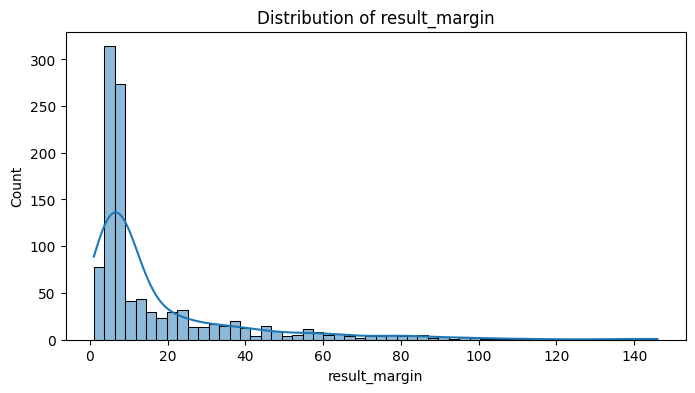

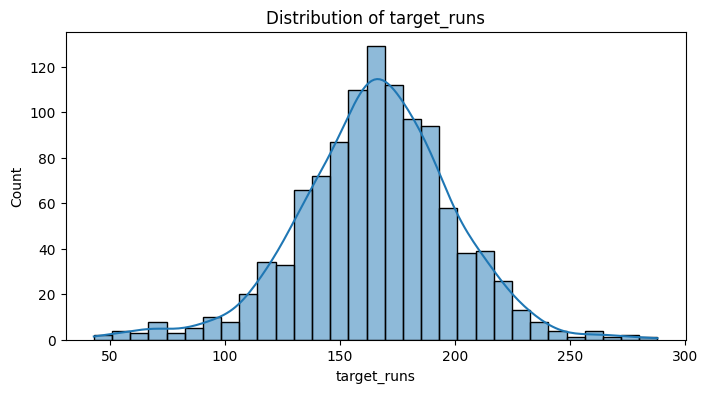

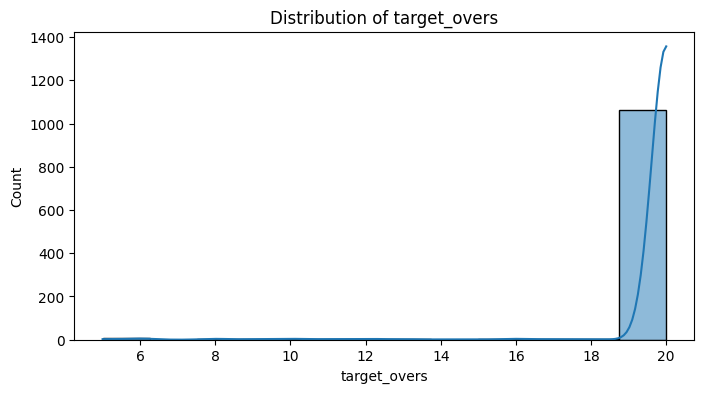

In [ ]:
# visualizing numerical cols
for col in num_cols:
  plt.figure(figsize=(8, 4))
  sns.histplot(data=df, x=col, kde=True)
  plt.title(f"Distribution of {col}");

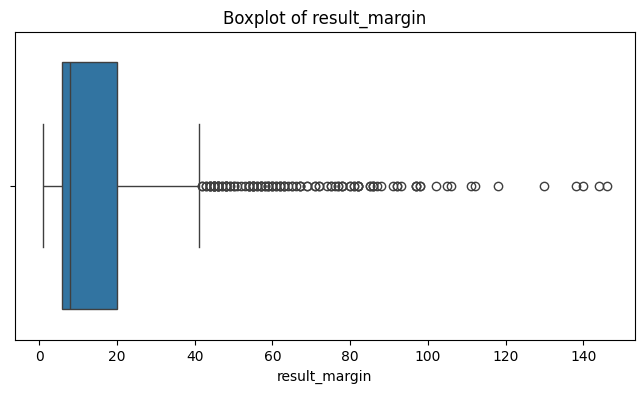

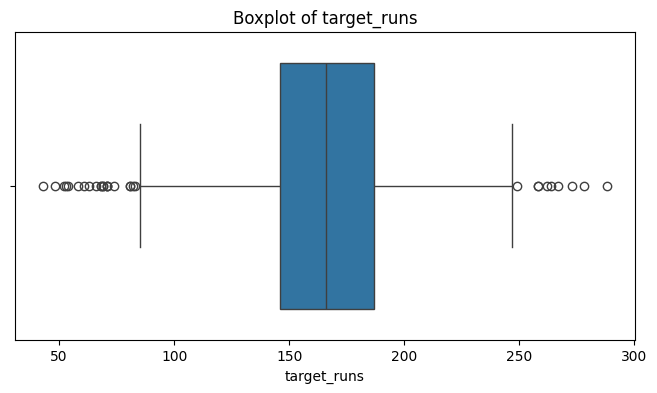

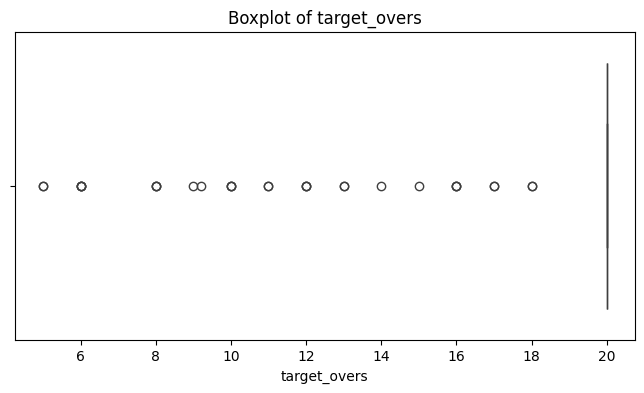

In [ ]:
# checking for outliers/anamolies
for col in num_cols:
  plt.figure(figsize=(8, 4))
  sns.boxplot(x=df[col])
  plt.title(f"Boxplot of {col}");

In [ ]:
# checking unique values and count of values for categorical columns
cat_cols = clean.select_dtypes(include='object').columns

for col in cat_cols:
    print("\n", col)
    print("Unique:", clean[col].nunique())
    print(clean[col].value_counts().head(10))


 city
Unique: 37
city
Mumbai        173
Kolkata        93
Delhi          90
Chennai        85
Hyderabad      77
Bangalore      65
Chandigarh     61
Jaipur         57
Pune           51
Unknown        51
Name: count, dtype: int64

 match_type
Unique: 8
match_type
League                1029
Final                   17
Qualifier 2             14
Qualifier 1             14
Eliminator              11
Semi Final               6
Elimination Final        3
3rd Place Play-Off       1
Name: count, dtype: int64

 player_of_match
Unique: 292
player_of_match
AB de Villiers    25
CH Gayle          22
RG Sharma         19
DA Warner         18
V Kohli           18
MS Dhoni          17
RA Jadeja         16
YK Pathan         16
SR Watson         16
AD Russell        15
Name: count, dtype: int64

 venue
Unique: 58
venue
Eden Gardens                                  77
Wankhede Stadium                              73
M Chinnaswamy Stadium                         65
Feroz Shah Kotla                         

In [ ]:
# result analysis
clean['result'].value_counts()

,count
result,
wickets,578
runs,498
tie,14
no result,5


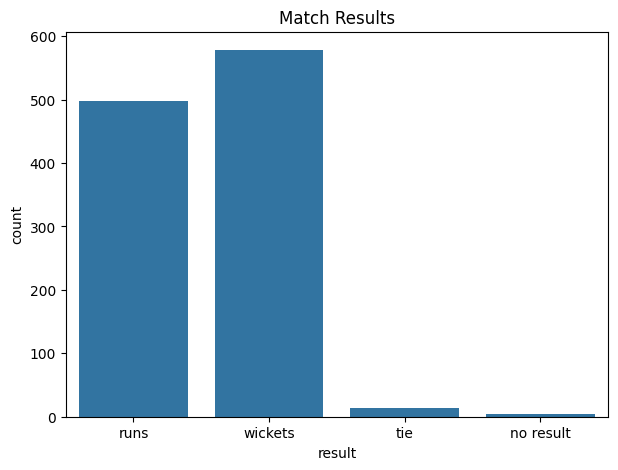

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=clean, x='result')
plt.title("Match Results");

In [ ]:
# toss analysis
clean['toss_decision'].value_counts()

,count
toss_decision,
field,704
bat,391


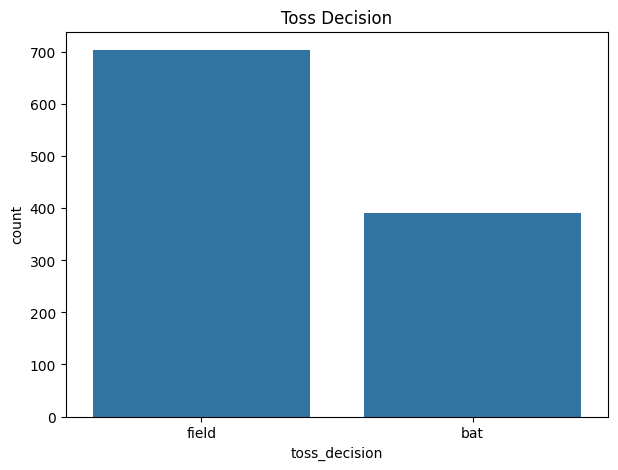

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=clean, x='toss_decision')
plt.title("Toss Decision");

In [ ]:
# checking whether winning the toss leads to winning the match
toss_match = clean['toss_winner'] == clean['winner']
toss_match.mean()*100

np.float64(50.593607305936075)

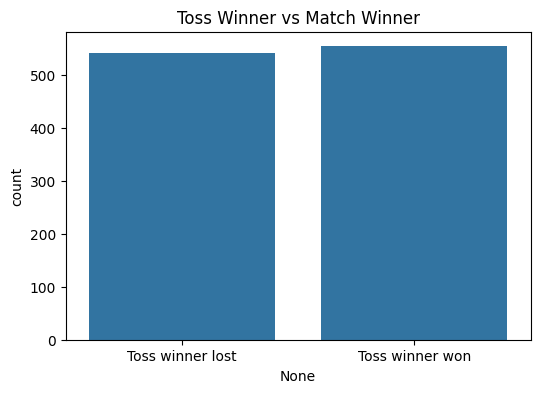

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x=toss_match.map({
        True: 'Toss winner won',
        False: 'Toss winner lost'
    })
)
plt.title("Toss Winner vs Match Winner");

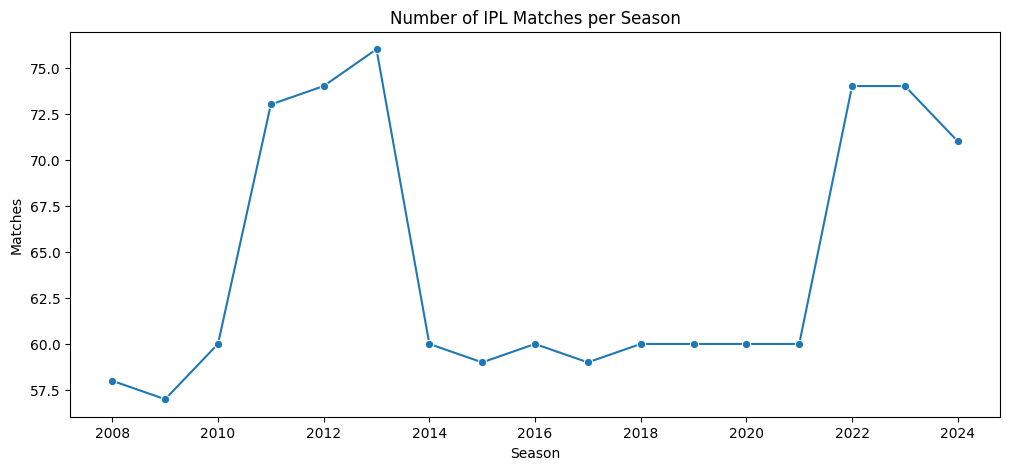

In [ ]:
# mathes per season
matches_per_season = (clean.groupby('season').size().reset_index(name='matches'))

plt.figure(figsize=(12, 5))
sns.lineplot(data=matches_per_season, x='season', y='matches',marker='o')
plt.title("Number of IPL Matches per Season")
plt.xlabel("Season")
plt.ylabel("Matches");

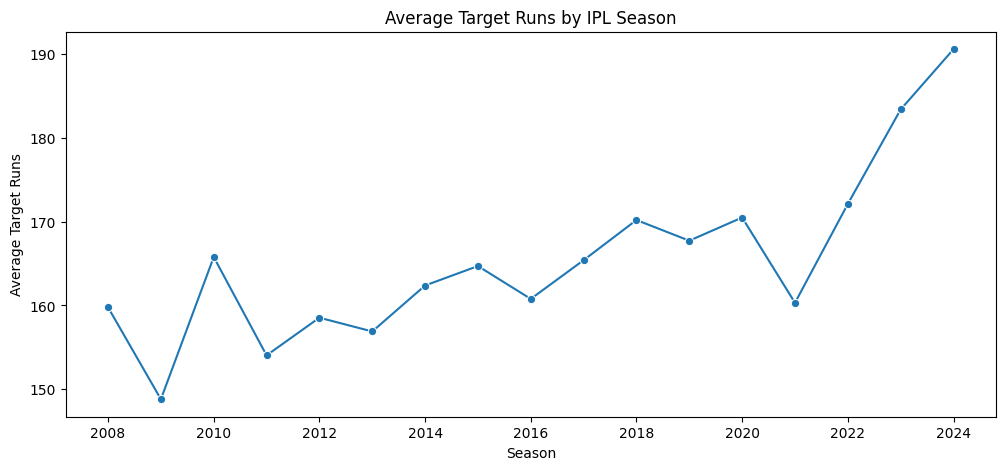

In [ ]:
# average target runs per season
season_runs = (clean.groupby('season')['target_runs'].mean())

plt.figure(figsize=(12, 5))
sns.lineplot(x=season_runs.index, y=season_runs.values, marker='o')
plt.title("Average Target Runs by IPL Season")
plt.xlabel("Season")
plt.ylabel("Average Target Runs");

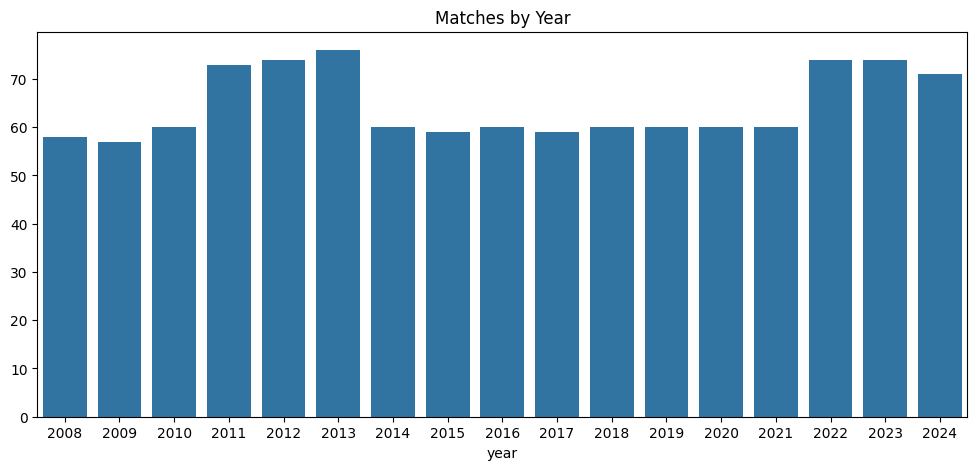

In [ ]:
# matches played across the years
clean['year'] = clean['date'].dt.year

year_counts = clean['year'].value_counts().sort_index()

plt.figure(figsize=(12, 5))
sns.barplot(x=year_counts.index, y=year_counts.values)
plt.title("Matches by Year");

In [ ]:
# teams analysis
teams = sorted(set(clean['team1']) | set(clean['team2']))
len(teams), teams

(15,
 ['Chennai Super Kings',
  'Deccan Chargers',
  'Delhi Capitals',
  'Gujarat Lions',
  'Gujarat Titans',
  'Kochi Tuskers Kerala',
  'Kolkata Knight Riders',
  'Lucknow Super Giants',
  'Mumbai Indians',
  'Pune Warriors',
  'Punjab Kings',
  'Rajasthan Royals',
  'Rising Pune Supergiants',
  'Royal Challengers Bengaluru',
  'Sunrisers Hyderabad'])

In [ ]:
# team appearances
team1_counts = clean['team1'].value_counts()
team2_counts = clean['team2'].value_counts()

team_appearances = (team1_counts.add(team2_counts, fill_value=0).sort_values(ascending=False))

team_appearances.head(15)

,count
Mumbai Indians,261
Royal Challengers Bengaluru,255
Delhi Capitals,252
Kolkata Knight Riders,251
Punjab Kings,246
Chennai Super Kings,238
Rajasthan Royals,221
Sunrisers Hyderabad,182
Deccan Chargers,75
Pune Warriors,46


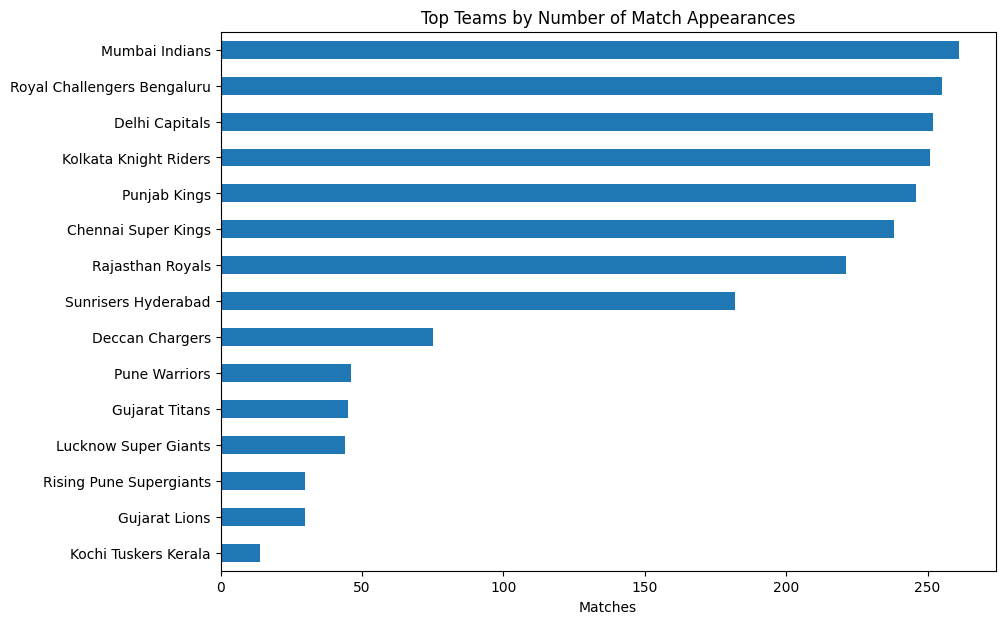

In [ ]:
plt.figure(figsize=(10, 7))
team_appearances.head(15).sort_values().plot(kind='barh')
plt.title("Top Teams by Number of Match Appearances")
plt.xlabel("Matches");

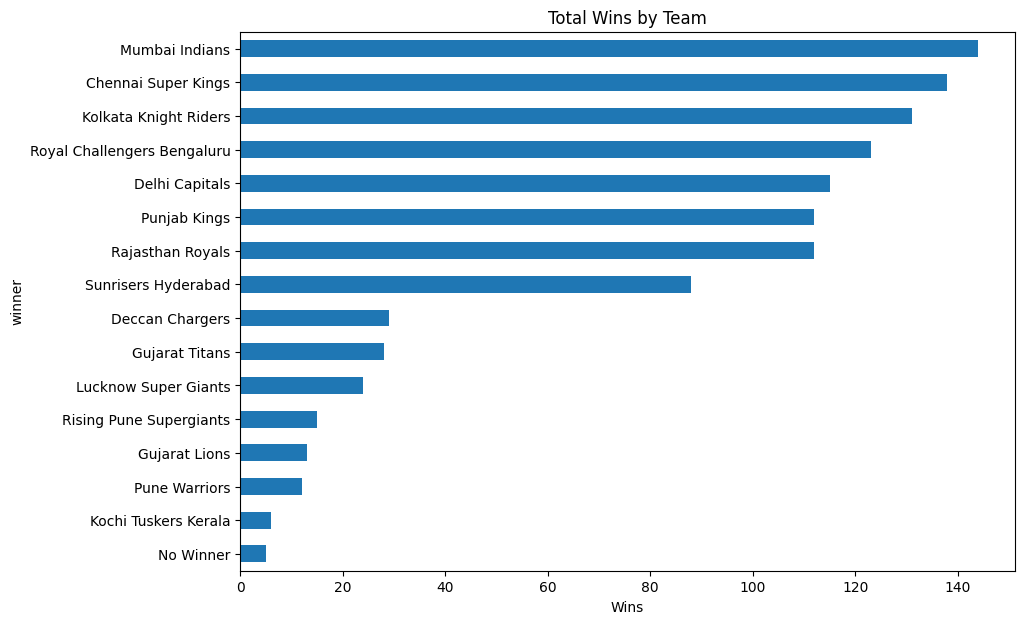

In [ ]:
# team wins
wins = clean['winner'].value_counts()

plt.figure(figsize=(10, 7))
wins.sort_values().plot(kind='barh')
plt.title("Total Wins by Team")
plt.xlabel("Wins");

In [ ]:
# player of the match analysis
pom = clean['player_of_match'].value_counts()
pom.head(15)

,count
player_of_match,
AB de Villiers,25
CH Gayle,22
RG Sharma,19
DA Warner,18
V Kohli,18
MS Dhoni,17
RA Jadeja,16
YK Pathan,16
SR Watson,16


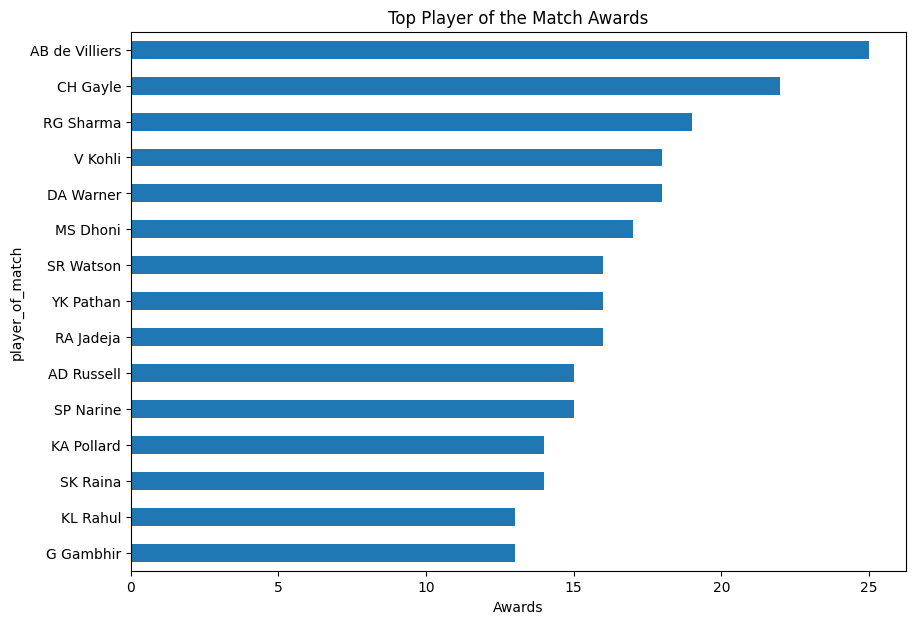

In [ ]:
plt.figure(figsize=(10, 7))
pom.head(15).sort_values().plot(kind='barh')
plt.title("Top Player of the Match Awards")
plt.xlabel("Awards");

In [ ]:
# venue analysis
venue_counts = clean['venue'].value_counts()
venue_counts.head(15)

,count
venue,
Eden Gardens,77
Wankhede Stadium,73
M Chinnaswamy Stadium,65
Feroz Shah Kotla,60
"Rajiv Gandhi International Stadium, Uppal",49
"MA Chidambaram Stadium, Chepauk",48
Sawai Mansingh Stadium,47
Dubai International Cricket Stadium,46
"Wankhede Stadium, Mumbai",45


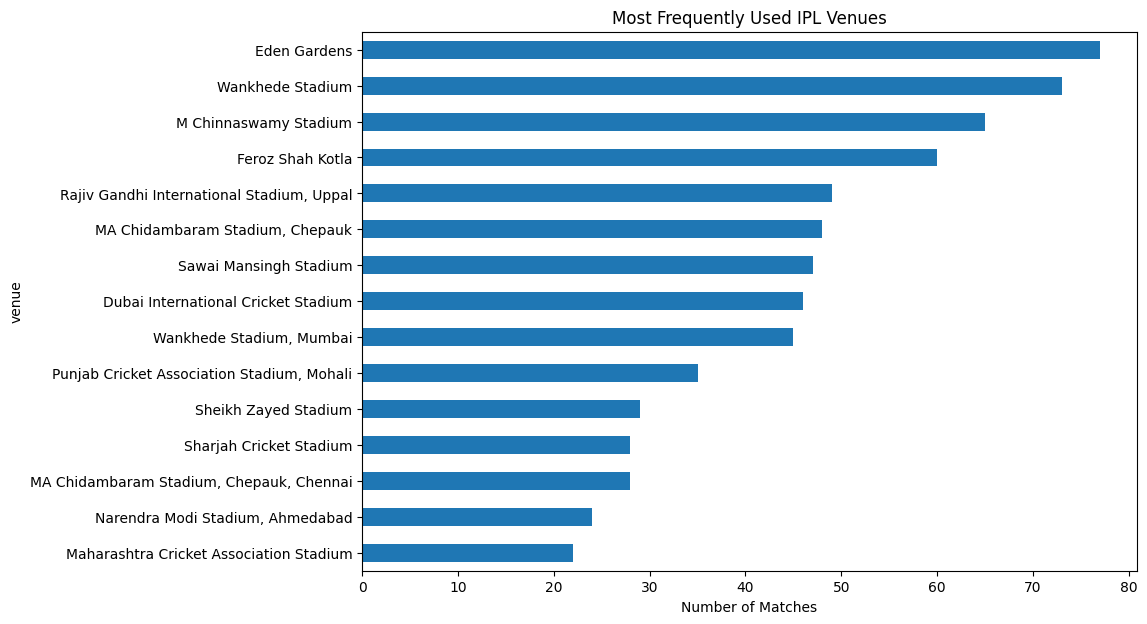

In [ ]:
plt.figure(figsize=(10, 7))
venue_counts.head(15).sort_values().plot(kind='barh')
plt.title("Most Frequently Used IPL Venues")
plt.xlabel("Number of Matches");

In [ ]:
# city analysis
city_counts = clean['city'].value_counts()
city_counts.head(15)

,count
city,
Mumbai,173
Kolkata,93
Delhi,90
Chennai,85
Hyderabad,77
Bangalore,65
Chandigarh,61
Jaipur,57
Pune,51


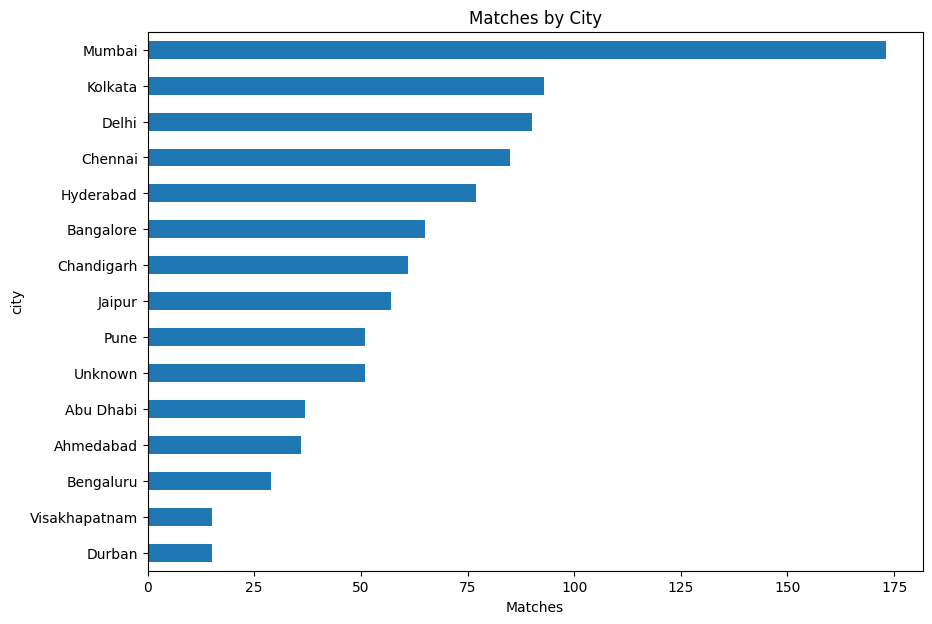

In [ ]:
plt.figure(figsize=(10, 7))
city_counts.head(15).sort_values().plot(kind='barh')
plt.title("Matches by City")
plt.xlabel("Matches");

In [ ]:
# super over analysis
clean['super_over'].value_counts()

,count
super_over,
N,1081
Y,14


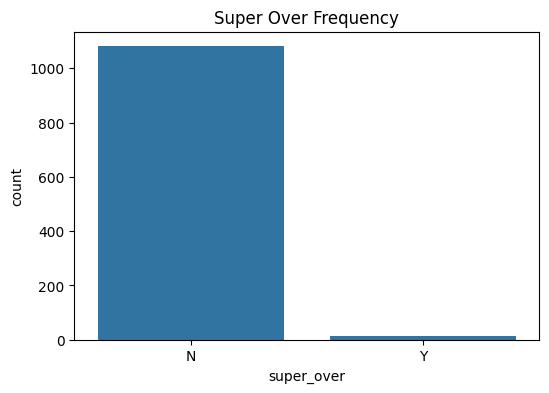

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='super_over')
plt.title("Super Over Frequency");

In [ ]:
# D/L method analysis
clean['method'].value_counts(dropna=False)

,count
method,
No interruption,1074
D/L,21


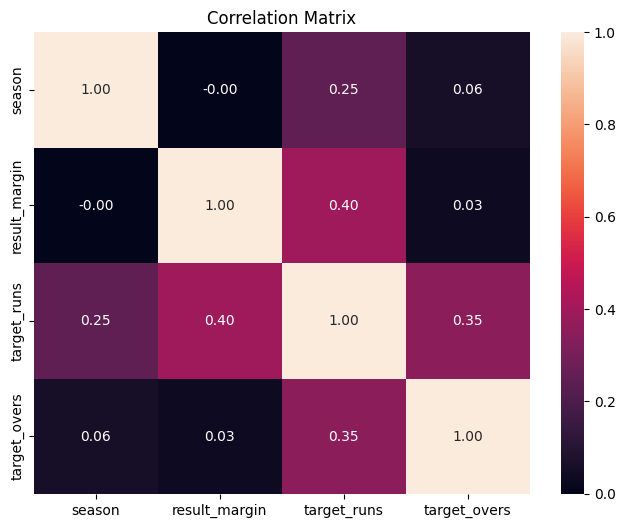

In [ ]:
# correlation analysis
corr = clean[['season', 'result_margin', 'target_runs', 'target_overs']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f')
plt.title("Correlation Matrix");

In [ ]:
# Build team-level metrics
records = []

for team in teams:
    team_games = clean[(clean.team1 == team) | (clean.team2 == team)]
    completed = team_games[team_games.winner != "No Winner"]
    wins = (completed.winner == team).sum()
    matches = len(completed)
    toss_wins = (team_games.toss_winner == team).sum()
    toss_match_wins = ((team_games.toss_winner == team) & (team_games.winner == team)).sum()

    # Victory margins by result type.
    wins_runs = completed[(completed.winner == team) & (completed.result == "runs")]["result_margin"].dropna()
    wins_wkts = completed[(completed.winner == team) & (completed.result == "wickets")]["result_margin"].dropna()

    venue_counts = team_games["venue"].value_counts()
    top3 = set(venue_counts.head(3).index)
    top3_games = completed[completed.venue.isin(top3)]
    other_games = completed[~completed.venue.isin(top3)]
    top3_win_pct = (top3_games.winner == team).mean() if len(top3_games) else 0.5
    other_win_pct = (other_games.winner == team).mean() if len(other_games) else 0.5

    home = completed[completed.city.isin(HOME_CITIES.get(team, set()))]
    away = completed[~completed.city.isin(HOME_CITIES.get(team, set()))]

    records.append({
        "team": team,
        "matches": matches,
        "win_pct": wins / matches if matches else 0.5,
        "avg_run_margin": wins_runs.mean() if len(wins_runs) else 0,
        "avg_wicket_margin": wins_wkts.mean() if len(wins_wkts) else 0,
        "toss_win_match_win_ratio": toss_match_wins / toss_wins if toss_wins else 0.5,
        "home_win_pct": (home.winner == team).mean() if len(home) else 0.5,
        "away_win_pct": (away.winner == team).mean() if len(away) else 0.5,
        "venue_familiarity_effect": top3_win_pct - other_win_pct,
        "top3_venue_win_pct": top3_win_pct,
        "other_venue_win_pct": other_win_pct
    })

team_metrics = pd.DataFrame(records).set_index("team")
cluster_features = [
    "win_pct", "avg_run_margin", "avg_wicket_margin",
    "toss_win_match_win_ratio", "home_win_pct", "away_win_pct",
    "venue_familiarity_effect"
]

team_metrics

,matches,win_pct,avg_run_margin,avg_wicket_margin,toss_win_match_win_ratio,home_win_pct,away_win_pct,venue_familiarity_effect,top3_venue_win_pct,other_venue_win_pct
team,,,,,,,,,,
Chennai Super Kings,237,0.582278,34.943662,6.029851,0.614754,0.704225,0.530120,0.150049,0.684211,0.534161
Deccan Chargers,75,0.386667,23.388889,6.545455,0.441860,0.166667,0.456140,-0.218085,0.250000,0.468085
Delhi Capitals,250,0.460000,25.630435,6.227273,0.469231,0.456790,0.461538,-0.011474,0.452381,0.463855
Gujarat Lions,30,0.433333,1.000000,5.416667,0.666667,0.357143,0.500000,-0.185520,0.352941,0.538462
Gujarat Titans,45,0.622222,34.181818,5.764706,0.636364,0.562500,0.655172,-0.140000,0.560000,0.700000
Kochi Tuskers Kerala,14,0.428571,11.500000,7.500000,0.500000,0.400000,0.444444,-0.125000,0.375000,0.500000
Kolkata Knight Riders,251,0.521912,33.592593,6.197368,0.557377,0.590909,0.484663,0.105595,0.585859,0.480263
Lucknow Super Giants,43,0.558140,24.437500,5.375000,0.526316,0.538462,0.566667,0.067100,0.590909,0.523810
Mumbai Indians,261,0.551724,32.971831,6.197183,0.545455,0.615385,0.509554,0.129586,0.632653,0.503067


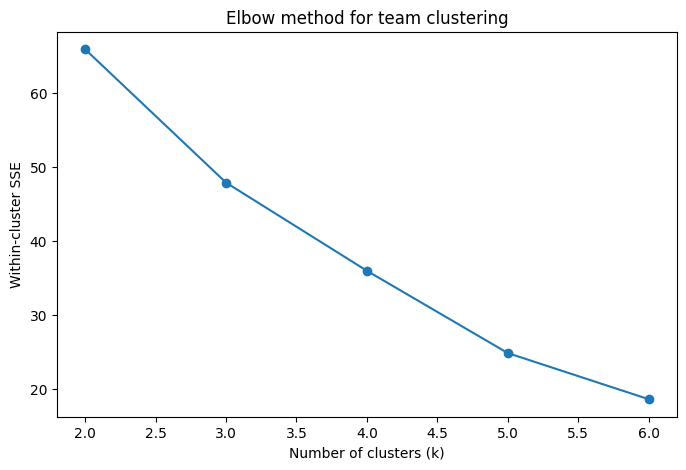

In [ ]:
scaler_cluster = StandardScaler()
X_cluster = scaler_cluster.fit_transform(team_metrics[cluster_features])

inertias = []
K = range(2, 7)
for k in K:
    inertias.append(KMeans(n_clusters=k, random_state=42, n_init=20).fit(X_cluster).inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(K), inertias, marker="o")
plt.title("Elbow method for team clustering")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster SSE");

In [ ]:
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=20)
team_metrics["cluster"] = kmeans.fit_predict(X_cluster)

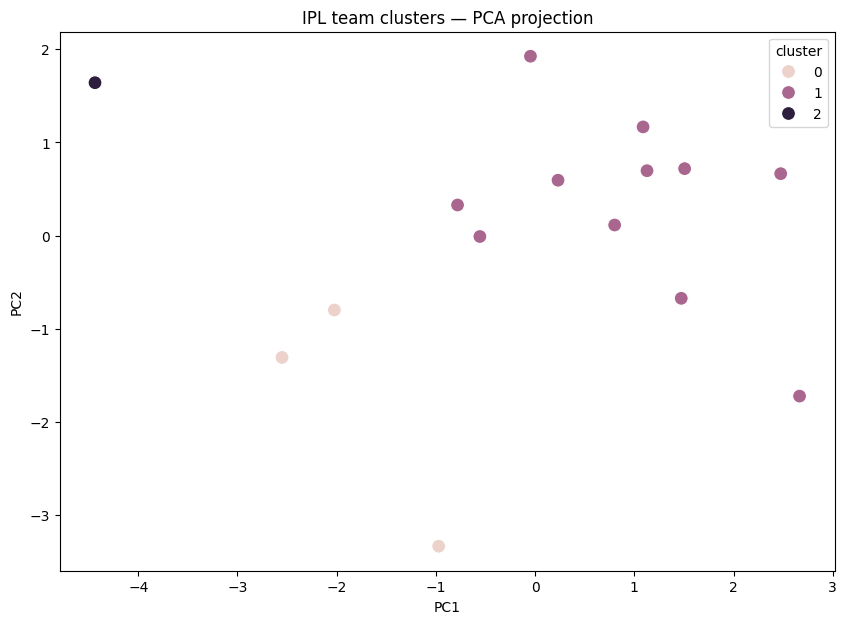

In [ ]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_cluster)
team_metrics["PC1"], team_metrics["PC2"] = coords[:,0], coords[:,1]

plt.figure(figsize=(10, 7))
sns.scatterplot(data=team_metrics, x="PC1", y="PC2", hue="cluster", s=100)
plt.title("IPL team clusters — PCA projection");

In [ ]:
cluster_profile = team_metrics.groupby("cluster")[cluster_features].mean().round(3)
display(team_metrics.sort_values(["cluster", "win_pct"], ascending=[True, False]))
display(cluster_profile)

,matches,win_pct,avg_run_margin,avg_wicket_margin,toss_win_match_win_ratio,home_win_pct,away_win_pct,venue_familiarity_effect,top3_venue_win_pct,other_venue_win_pct,cluster,PC1,PC2
team,,,,,,,,,,,,,
Gujarat Lions,30,0.433333,1.000000,5.416667,0.666667,0.357143,0.500000,-0.185520,0.352941,0.538462,0,-0.972184,-3.334057
Kochi Tuskers Kerala,14,0.428571,11.500000,7.500000,0.500000,0.400000,0.444444,-0.125000,0.375000,0.500000,0,-2.023722,-0.798904
Deccan Chargers,75,0.386667,23.388889,6.545455,0.441860,0.166667,0.456140,-0.218085,0.250000,0.468085,0,-2.551138,-1.307901
Gujarat Titans,45,0.622222,34.181818,5.764706,0.636364,0.562500,0.655172,-0.140000,0.560000,0.700000,1,2.665361,-1.722802
Chennai Super Kings,237,0.582278,34.943662,6.029851,0.614754,0.704225,0.530120,0.150049,0.684211,0.534161,1,2.475392,0.664312
Lucknow Super Giants,43,0.558140,24.437500,5.375000,0.526316,0.538462,0.566667,0.067100,0.590909,0.523810,1,1.472796,-0.673293
Mumbai Indians,261,0.551724,32.971831,6.197183,0.545455,0.615385,0.509554,0.129586,0.632653,0.503067,1,1.507081,0.718391
Kolkata Knight Riders,251,0.521912,33.592593,6.197368,0.557377,0.590909,0.484663,0.105595,0.585859,0.480263,1,1.127766,0.696286
Rajasthan Royals,219,0.511416,30.837209,5.835821,0.500000,0.649123,0.462963,0.181100,0.633803,0.452703,1,1.088000,1.166243


,win_pct,avg_run_margin,avg_wicket_margin,toss_win_match_win_ratio,home_win_pct,away_win_pct,venue_familiarity_effect
cluster,,,,,,,
0,0.416,11.963,6.487,0.536,0.308,0.467,-0.176
1,0.521,29.625,6.133,0.529,0.563,0.503,0.087
2,0.267,23.167,6.000,0.150,0.250,0.276,0.030


In [ ]:
# Data-driven labels based on cluster average win percentage and margin.
ranked_clusters = cluster_profile["win_pct"].sort_values().index.tolist()
labels = {
    ranked_clusters[0]: "Inconsistent",
    ranked_clusters[1]: "Balanced",
    ranked_clusters[2]: "Dominant"
}
team_metrics["cluster_label"] = team_metrics["cluster"].map(labels)
display(team_metrics[["win_pct", "venue_familiarity_effect", "cluster_label"]].sort_values("win_pct", ascending=False))

,win_pct,venue_familiarity_effect,cluster_label
team,,,
Gujarat Titans,0.622222,-0.140000,Dominant
Chennai Super Kings,0.582278,0.150049,Dominant
Lucknow Super Giants,0.558140,0.067100,Dominant
Mumbai Indians,0.551724,0.129586,Dominant
Kolkata Knight Riders,0.521912,0.105595,Dominant
Rajasthan Royals,0.511416,0.181100,Dominant
Rising Pune Supergiants,0.500000,0.203620,Dominant
Royal Challengers Bengaluru,0.488095,0.026959,Dominant
Sunrisers Hyderabad,0.483516,0.241123,Dominant


In [ ]:
model_df = clean[clean.winner != "No Winner"].copy()
model_df["target"] = (model_df["winner"] == model_df["team1"]).astype(int)

# Explicit pre-match interactions
model_df["team1_venue"] = model_df["team1"] + "__" + model_df["venue"]
model_df["team2_venue"] = model_df["team2"] + "__" + model_df["venue"]
model_df["team1_toss_interaction"] = model_df["team1"] + "__toss_" + model_df["team1_won_toss"].astype(str)
model_df["team2_toss_interaction"] = model_df["team2"] + "__toss_" + model_df["team2_won_toss"].astype(str)
model_df["team1_vs_team2"] = model_df["team1"] + "__vs__" + model_df["team2"]

feature_cols = [
    "team1", "team2", "venue", "toss_winner", "toss_decision", "season_phase",
    "match_importance", "team1_venue", "team2_venue",
    "team1_toss_interaction", "team2_toss_interaction", "team1_vs_team2",
    "team1_win_rate_prior", "team2_win_rate_prior",
    "team1_toss_win_rate_prior", "team2_toss_win_rate_prior",
    "venue_matches_team1_prior", "venue_matches_team2_prior",
    "venue_win_rate_team1_prior", "venue_win_rate_team2_prior",
    "team1_home", "team2_home", "home_advantage",
    "team1_won_toss", "team2_won_toss"
]

cat_cols = [c for c in feature_cols if model_df[c].dtype == "object"]
num_cols = [c for c in feature_cols if c not in cat_cols]

split = int(len(model_df) * 0.80)
train, test = model_df.iloc[:split], model_df.iloc[split:]
X_train, X_test = train[feature_cols], test[feature_cols]
y_train, y_test = train["target"], test["target"]

pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)
])

def make_logistic(C=1.0, penalty="l2"):
    steps = [("pre", pre)]
    if SMOTE is not None:
        steps.append(("smote", SMOTE(random_state=42)))
    steps.append(("model", LogisticRegression(
        C=C, penalty=penalty, solver="liblinear", max_iter=2000, random_state=42
    )))
    return ImbPipeline(steps) if SMOTE is not None else Pipeline(steps)

results_lr = []
lr_models = {}
for penalty in ["l1", "l2"]:
    pipe = make_logistic(C=1.0, penalty=penalty)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:,1]
    metrics = {
        "Regularization": penalty.upper(),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    }
    results_lr.append(metrics)
    lr_models[penalty] = pipe

lr_results = pd.DataFrame(results_lr).set_index("Regularization")
display(lr_results.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Regularization,,,,,
L1,0.4862,0.5000,0.4554,0.4766,0.5158
L2,0.4908,0.5059,0.3839,0.4365,0.5115


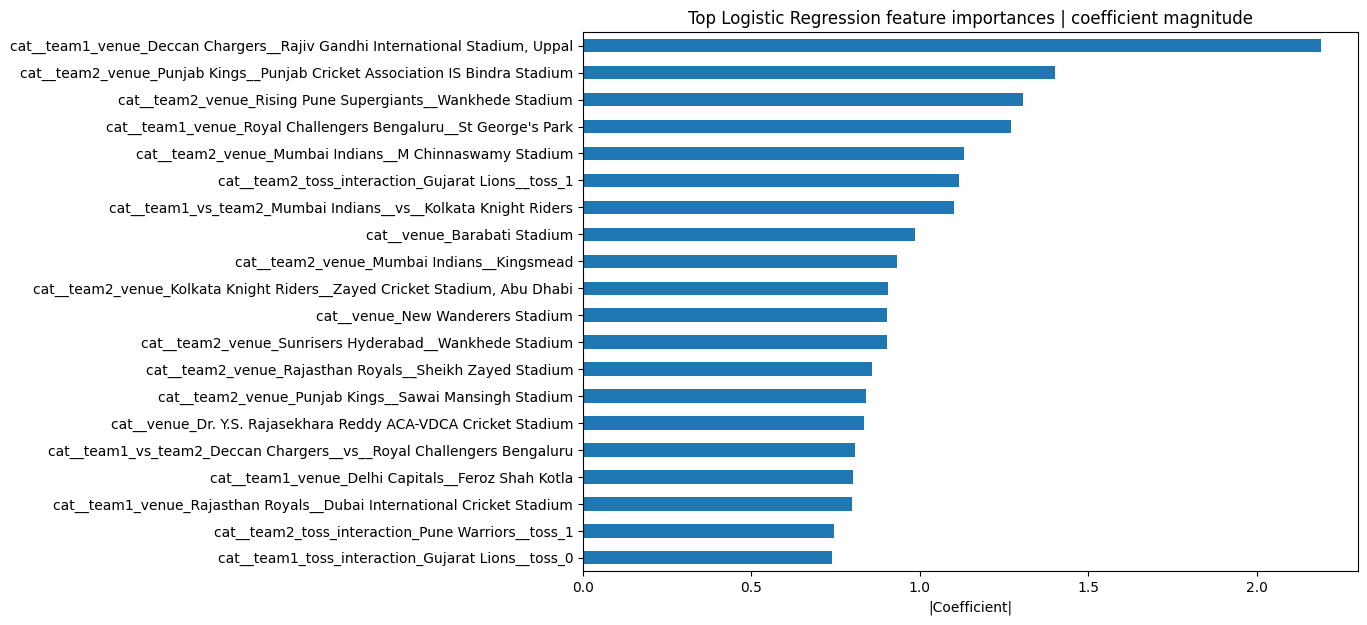

In [ ]:
# Feature importance from L1 model: absolute coefficient magnitude.
best_lr = lr_models["l1"] if lr_results.loc["L1","ROC-AUC"] >= lr_results.loc["L2","ROC-AUC"] else lr_models["l2"]
feature_names = best_lr.named_steps["pre"].get_feature_names_out()
coef = best_lr.named_steps["model"].coef_[0]
importance = pd.Series(np.abs(coef), index=feature_names).sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 7))
importance.sort_values().plot(kind="barh")
plt.title("Top Logistic Regression feature importances | coefficient magnitude")
plt.xlabel("|Coefficient|");

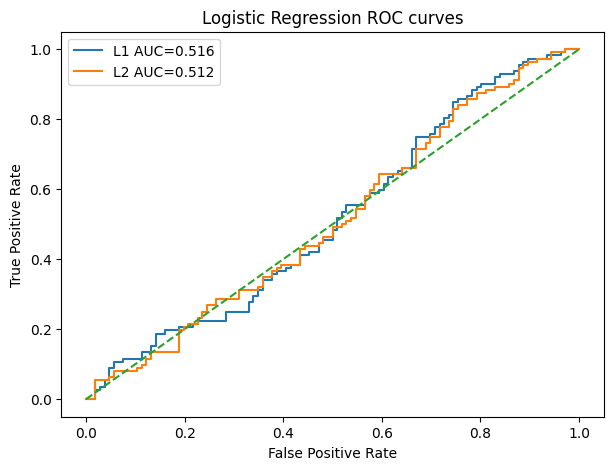

In [ ]:
# ROC and Precision-Recall curves
plt.figure(figsize=(7, 5))
for penalty, pipe in lr_models.items():
    p = pipe.predict_proba(X_test)[:,1]
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{penalty.upper()} AUC={roc_auc_score(y_test,p):.3f}")
plt.plot([0,1],[0,1],"--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression ROC curves")
plt.legend();

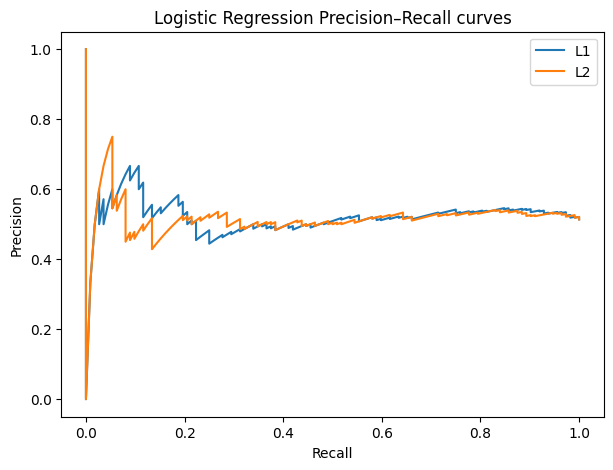

In [ ]:
plt.figure(figsize=(7, 5))
for penalty, pipe in lr_models.items():
    p = pipe.predict_proba(X_test)[:,1]
    precision, recall, _ = precision_recall_curve(y_test, p)
    plt.plot(recall, precision, label=penalty.upper())
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Logistic Regression Precision–Recall curves")
plt.legend();

In [ ]:
completed = clean[clean.winner != "No Winner"].copy()

# Team-season match records
team_season_rows = []
for _, r in completed.iterrows():
    for team, opp in [(r.team1, r.team2), (r.team2, r.team1)]:
        team_season_rows.append({
            "season": r.season, "team": team, "opponent": opp,
            "won": int(r.winner == team),
            "toss_won": int(r.toss_winner == team),
            "venue": r.venue
        })

ts = pd.DataFrame(team_season_rows)
team_season = ts.groupby(["season","team"]).agg(
    matches=("won","size"),
    wins=("won","sum"),
    toss_wins=("toss_won","sum")
).reset_index()
team_season["win_pct"] = team_season["wins"] / team_season["matches"]
team_season["toss_win_pct"] = team_season["toss_wins"] / team_season["matches"]
team_season["toss_luck"] = team_season["win_pct"] - team_season["toss_win_pct"]

In [ ]:
# Top-3 venue exposure per team, computed from all historical matches in this dataset.
top3_map = {}
for team in teams:
    vc = clean[(clean.team1 == team) | (clean.team2 == team)]["venue"].value_counts()
    top3_map[team] = set(vc.head(3).index)

ts["top3_venue"] = [v in top3_map[t] for t,v in zip(ts.team, ts.venue)]
venue_exp = ts.groupby(["season","team"])["top3_venue"].mean().reset_index(name="top3_venue_exposure")
team_season = team_season.merge(venue_exp, on=["season","team"], how="left")

In [ ]:
# Opponent seasonal strength
opp_strength = team_season[["season","team","win_pct"]].rename(
    columns={"team":"opponent","win_pct":"opponent_win_pct"}
)
ts2 = ts.merge(opp_strength, on=["season","opponent"], how="left")
opp = ts2.groupby(["season","team"])["opponent_win_pct"].mean().reset_index(name="opponent_strength")
team_season = team_season.merge(opp, on=["season","team"], how="left")

trend_rows = []
for team, g in team_season.groupby("team"):
    g = g.sort_values("season")
    if len(g) >= 3:
        X = g[["season"]].values
        y = g["win_pct"].values
        lr = LinearRegression().fit(X, y)
        next_season = int(g.season.max() + 1)
        pred_next = float(np.clip(lr.predict([[next_season]])[0], 0, 1))
        trend_rows.append({
            "team": team, "seasons": len(g), "slope_per_year": lr.coef_[0],
            "intercept": lr.intercept_, "predicted_next_season_win_pct": pred_next
        })

trends = pd.DataFrame(trend_rows).sort_values("slope_per_year", ascending=False)
display(trends)

,team,seasons,slope_per_year,intercept,predicted_next_season_win_pct
1,Deccan Chargers,5,0.011369,-22.471667,0.414226
4,Kolkata Knight Riders,17,0.006473,-12.532817,0.575415
2,Delhi Capitals,17,0.002152,-3.884579,0.473647
10,Royal Challengers Bengaluru,17,0.000642,-0.812223,0.488127
9,Rajasthan Royals,15,-0.004448,9.471757,0.464769
0,Chennai Super Kings,15,-0.005217,11.094551,0.530271
8,Punjab Kings,17,-0.006903,14.367441,0.388357
6,Mumbai Indians,17,-0.007581,15.825438,0.473216
11,Sunrisers Hyderabad,12,-0.016207,33.189955,0.370872
7,Pune Warriors,3,-0.028846,58.307692,0.211538


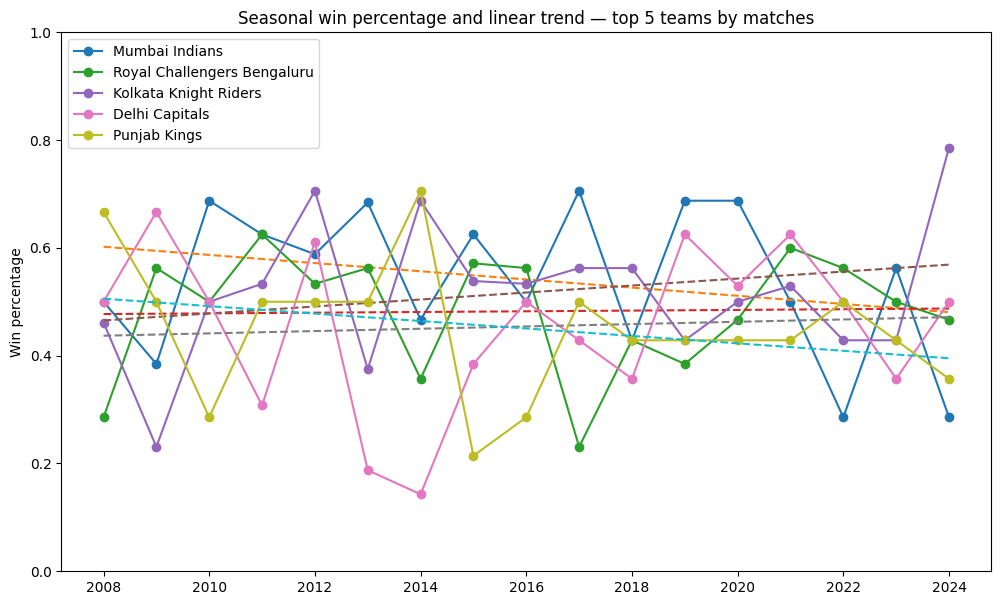

In [ ]:
top5 = team_season.groupby("team")["matches"].sum().nlargest(5).index.tolist()
plt.figure(figsize=(12, 7))
for team in top5:
    g = team_season[team_season.team == team].sort_values("season")
    plt.plot(g.season, g.win_pct, marker="o", label=team)
    lr = LinearRegression().fit(g[["season"]], g.win_pct)
    plt.plot(g.season, lr.predict(g[["season"]]), linestyle="--")
plt.ylim(0,1)
plt.ylabel("Win percentage")
plt.title("Seasonal win percentage and linear trend — top 5 teams by matches")
plt.legend();

In [ ]:
# Factor correlation with win percentage (association only).
factor_corr = team_season[[
    "win_pct","toss_luck","top3_venue_exposure","opponent_strength"
]].corr()["win_pct"].drop("win_pct").sort_values(ascending=False)
display(factor_corr.to_frame("correlation_with_win_pct"))

,correlation_with_win_pct
toss_luck,0.708060
top3_venue_exposure,0.032926
opponent_strength,-0.724727


In [ ]:
pom_df = clean[clean.player_of_match != "Unknown"].copy()

# Venue characteristics computed using historical matches, not the current match.
venue_stats = pom_df.groupby("venue").agg(
    matches=("id","count"),
    chase_wins=("result", lambda s: (s == "wickets").sum()),
    avg_target=("target_runs","mean"),
    shortened=("is_shortened_match","mean")
).reset_index()
venue_stats["chasing_bias"] = venue_stats["chase_wins"] / venue_stats["matches"]

In [ ]:
# Season/team strength.
season_strength = team_season[["season","team","win_pct"]].copy()
s1 = season_strength.rename(columns={"team":"team1","win_pct":"team1_strength"})
s2 = season_strength.rename(columns={"team":"team2","win_pct":"team2_strength"})
pom_df = pom_df.merge(s1, on=["season","team1"], how="left").merge(s2, on=["season","team2"], how="left")
pom_df = pom_df.merge(venue_stats[["venue","chasing_bias","avg_target","shortened"]], on="venue", how="left")

In [ ]:
# Historical PoM priors, calculated with only prior rows.
pom_venue = defaultdict(int)
pom_opp = defaultdict(int)
pom_season = defaultdict(int)
pom_player = defaultdict(int)
match_seen = defaultdict(int)

pom_features = []
for _, r in pom_df.sort_values(["date","id"]).iterrows():
    p = r.player_of_match
    opp = r.team2 if p in [] else None
    pom_features.append({
        "pom_global_prior": pom_player[p],
        "pom_venue_prior": pom_venue[(p, r.venue)],
        "pom_season_prior": pom_season[(p, r.season)]
    })
    pom_player[p] += 1
    pom_venue[(p, r.venue)] += 1
    pom_season[(p, r.season)] += 1

pom_hist = pd.DataFrame(pom_features, index=pom_df.sort_values(["date","id"]).index)
pom_df = pom_df.loc[pom_hist.index].copy()
pom_df[["pom_global_prior","pom_venue_prior","pom_season_prior"]] = pom_hist

pom_features_cols = [
    "chasing_bias","avg_target","shortened",
    "team1_strength","team2_strength",
    "pom_global_prior","pom_venue_prior","pom_season_prior"
]
pom_df[pom_features_cols] = pom_df[pom_features_cols].fillna(0)

In [ ]:
# Chronological split
psplit = int(len(pom_df)*0.8)
ptrain, ptest = pom_df.iloc[:psplit], pom_df.iloc[psplit:]

scaler_knn = StandardScaler()
Xptr = scaler_knn.fit_transform(ptrain[pom_features_cols])
Xpte = scaler_knn.transform(ptest[pom_features_cols])

In [ ]:
candidate_k = [3,5,7,9,11,15]
cv_scores = {}
for k in candidate_k:
    # Time-series-like validation: evaluate on the final 20% of training data.
    cut = int(len(ptrain)*0.8)
    knn_cv = KNeighborsClassifier(n_neighbors=k, weights="distance")
    knn_cv.fit(Xptr[:cut], ptrain.player_of_match.iloc[:cut])
    cv_scores[k] = knn_cv.score(Xptr[cut:], ptrain.player_of_match.iloc[cut:])

best_k = max(cv_scores, key=cv_scores.get)
knn = KNeighborsClassifier(n_neighbors=best_k, weights="distance")
knn.fit(Xptr, ptrain.player_of_match)

print("KNN k validation scores:", cv_scores)
print("Selected k:", best_k)
print("Exact top-1 accuracy on held-out matches:", round(knn.score(Xpte, ptest.player_of_match), 4))

KNN k validation scores: {3: 0.045714285714285714, 5: 0.045714285714285714, 7: 0.04, 9: 0.02857142857142857, 11: 0.022857142857142857, 15: 0.022857142857142857}
Selected k: 3
Exact top-1 accuracy on held-out matches: 0.0046


In [ ]:
# Example top-k candidate ranking for the first held-out match.
example_x = Xpte[:1]
dist, idx = knn.kneighbors(example_x)
weights = 1 / (dist[0] + 1e-9)
votes = defaultdict(float)
for w, i in zip(weights, idx[0]):
    votes[ptrain.player_of_match.iloc[i]] += w
top_candidates = pd.Series(votes).sort_values(ascending=False).head(5)
display(top_candidates.to_frame("similarity_weighted_vote"))

,similarity_weighted_vote
SV Samson,0.838003
UT Yadav,0.617075
DR Smith,0.584476


In [ ]:
# Historical decision effectiveness.
td = clean[clean.winner != "No Winner"].copy()
td["decision_won_match"] = (td["toss_winner"] == td["winner"]).astype(int)

decision_perf = td.groupby(["venue","season_phase","toss_decision"])["decision_won_match"].agg(["mean","count"]).reset_index()

In [ ]:
venue_dec = td.groupby(["venue","toss_decision"])["decision_won_match"].agg(["mean","count"]).reset_index()

def recommended_decision(row):
    x = decision_perf[(decision_perf.venue == row.venue) &
                      (decision_perf.season_phase == row.season_phase) &
                      (decision_perf["count"] >= 3)]
    if len(x) >= 2:
        return x.loc[x["mean"].idxmax(), "toss_decision"]
    x = venue_dec[(venue_dec.venue == row.venue) & (venue_dec["count"] >= 3)]
    if len(x):
        return x.loc[x["mean"].idxmax(), "toss_decision"]
    return "field"

td["recommended_decision"] = td.apply(recommended_decision, axis=1)

In [ ]:
# Reproducible synthetic weather proxy — NOT observed weather.
rng = np.random.default_rng(42)
weather_categories = np.array(["Clear","Cloudy","Humid","Rain_Risk"])
td["synthetic_weather"] = rng.choice(weather_categories, size=len(td), p=[0.45,0.20,0.25,0.10])

# Venue history features.
td["venue_avg_margin"] = td.groupby("venue")["result_margin"].transform("mean").fillna(0)
td["venue_chase_bias"] = td.groupby("venue")["result"].transform(lambda s: (s=="wickets").mean())
td["team1_strength"] = td.groupby("team1")["winner"].transform(lambda s: (s==s.name).mean()) if False else 0.5
# Use stable team-season strength from the team-level table.
strength_lookup = team_season.set_index(["season","team"])["win_pct"].to_dict()
td["team1_strength"] = [strength_lookup.get((r.season,r.team1),0.5) for _,r in td.iterrows()]
td["team2_strength"] = [strength_lookup.get((r.season,r.team2),0.5) for _,r in td.iterrows()]

tree_features = [
    "venue","season_phase","match_importance","synthetic_weather",
    "team1_strength","team2_strength","venue_avg_margin","venue_chase_bias"
]
Xtree = td[tree_features]
ytree = td["recommended_decision"]

tree_cat = ["venue","season_phase","match_importance","synthetic_weather"]
tree_num = ["team1_strength","team2_strength","venue_avg_margin","venue_chase_bias"]

tree_pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), tree_cat),
    ("num", StandardScaler(), tree_num)
])
tree = Pipeline([
    ("pre", tree_pre),
    ("model", DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=42))
])
tree.fit(Xtree, ytree)

tree_names = tree.named_steps["pre"].get_feature_names_out()
tree_imp = pd.Series(tree.named_steps["model"].feature_importances_, index=tree_names).sort_values(ascending=False)
display(tree_imp.head(15).to_frame("importance"))

,importance
num__venue_chase_bias,0.625235
num__venue_avg_margin,0.239231
"cat__venue_Arun Jaitley Stadium, Delhi",0.072381
"cat__venue_M Chinnaswamy Stadium, Bengaluru",0.042582
cat__venue_Sheikh Zayed Stadium,0.010319
num__team2_strength,0.007648
num__team1_strength,0.001908
cat__season_phase_Early,0.000696
cat__venue_Buffalo Park,0.000000
"cat__venue_Brabourne Stadium, Mumbai",0.000000


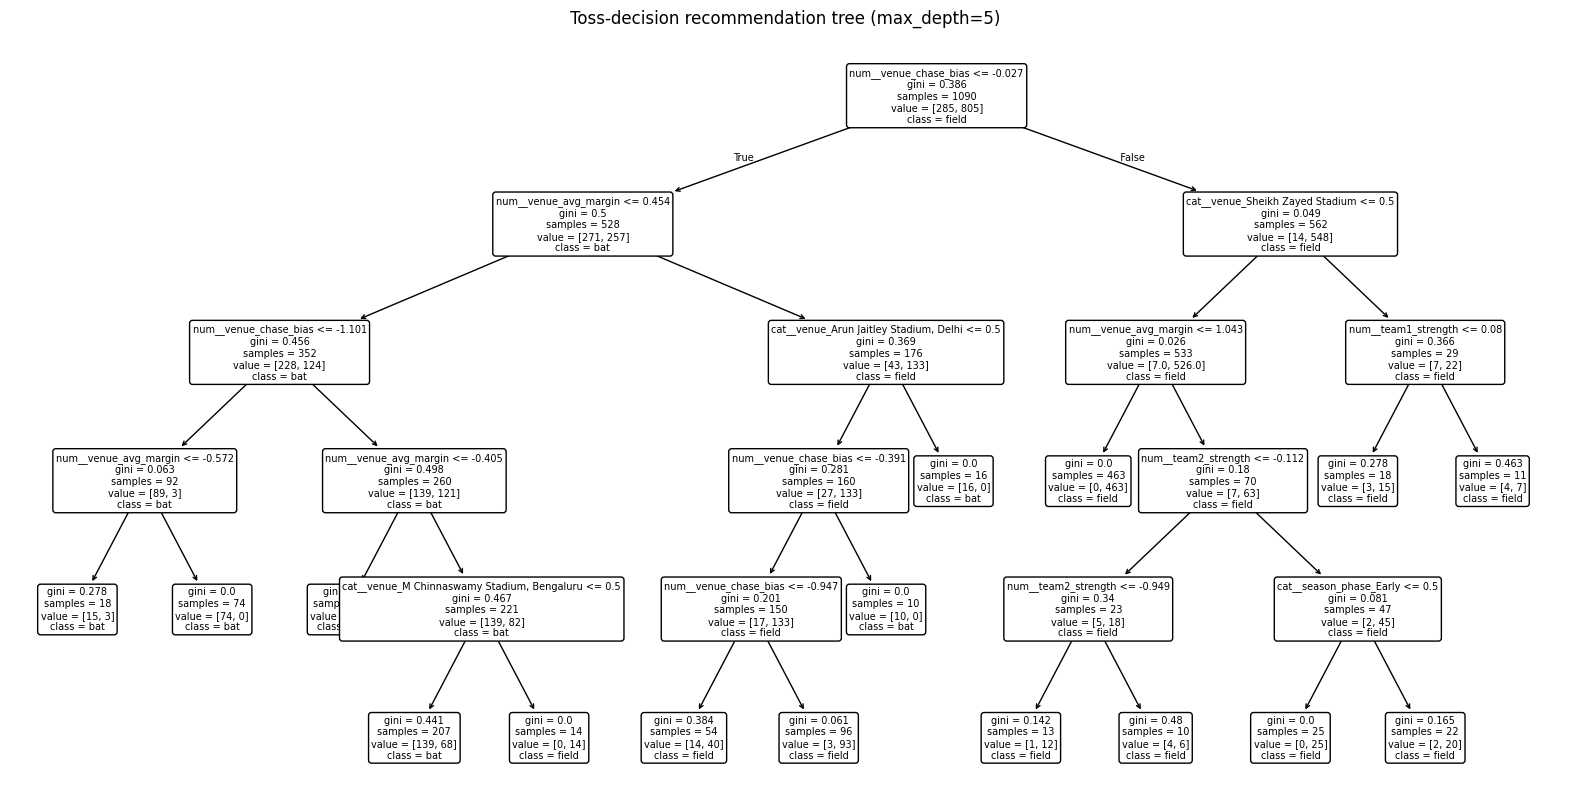

In [ ]:
plt.figure(figsize=(20,10))
plot_tree(tree.named_steps["model"], feature_names=tree_names, class_names=tree.named_steps["model"].classes_,
          filled=False, rounded=True, fontsize=7)
plt.title("Toss-decision recommendation tree (max_depth=5)");

In [ ]:
# Reuse the match-prediction train/test split and features.
rf_pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)
])

rf = Pipeline([
    ("pre", rf_pre),
    ("model", RandomForestClassifier(
        n_estimators=500, max_depth=None, min_samples_leaf=3,
        max_features="sqrt", class_weight="balanced", random_state=42, n_jobs=-1
    ))
])
rf.fit(X_train, y_train)
rf_prob = rf.predict_proba(X_test)[:,1]
rf_pred = (rf_prob >= 0.5).astype(int)

models = {
    "Random Forest": (rf_pred, rf_prob)
}

if XGBClassifier is not None:
    xgb = Pipeline([
        ("pre", rf_pre),
        ("model", XGBClassifier(
            n_estimators=400, max_depth=4, learning_rate=0.04,
            subsample=0.85, colsample_bytree=0.85,
            reg_lambda=2, objective="binary:logistic",
            eval_metric="logloss", random_state=42, n_jobs=4
        ))
    ])
    xgb.fit(X_train, y_train)
    xgb_prob = xgb.predict_proba(X_test)[:,1]
    xgb_pred = (xgb_prob >= 0.5).astype(int)
    models["XGBoost"] = (xgb_pred, xgb_prob)
else:
    xgb = None

# Probability-average ensemble.
if xgb is not None:
    ens_prob = (rf_prob + xgb_prob) / 2
    ens_pred = (ens_prob >= 0.5).astype(int)
    models["RF + XGBoost Ensemble"] = (ens_pred, ens_prob)

comparison = []
for name,(pred,prob) in models.items():
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test,pred),
        "Precision": precision_score(y_test,pred),
        "Recall": recall_score(y_test,pred),
        "F1": f1_score(y_test,pred),
        "ROC-AUC": roc_auc_score(y_test,prob)
    })
comparison = pd.DataFrame(comparison).sort_values("ROC-AUC", ascending=False)
display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
1,XGBoost,0.4954,0.5135,0.3393,0.4086,0.5139
2,RF + XGBoost Ensemble,0.5138,0.5441,0.3304,0.4111,0.5086
0,Random Forest,0.4725,0.4762,0.2679,0.3429,0.5017


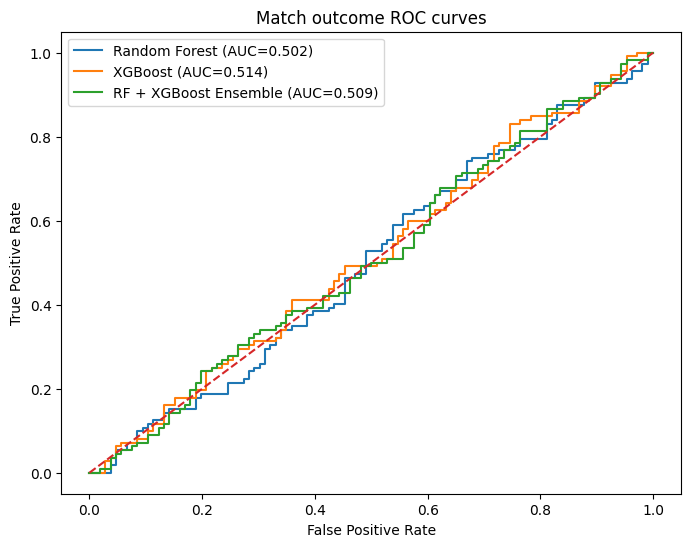

In [ ]:
plt.figure(figsize=(8,6))
for name,(pred,prob) in models.items():
    fpr,tpr,_ = roc_curve(y_test,prob)
    plt.plot(fpr,tpr,label=f"{name} (AUC={roc_auc_score(y_test,prob):.3f})")
plt.plot([0,1],[0,1],"--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Match outcome ROC curves")
plt.legend();

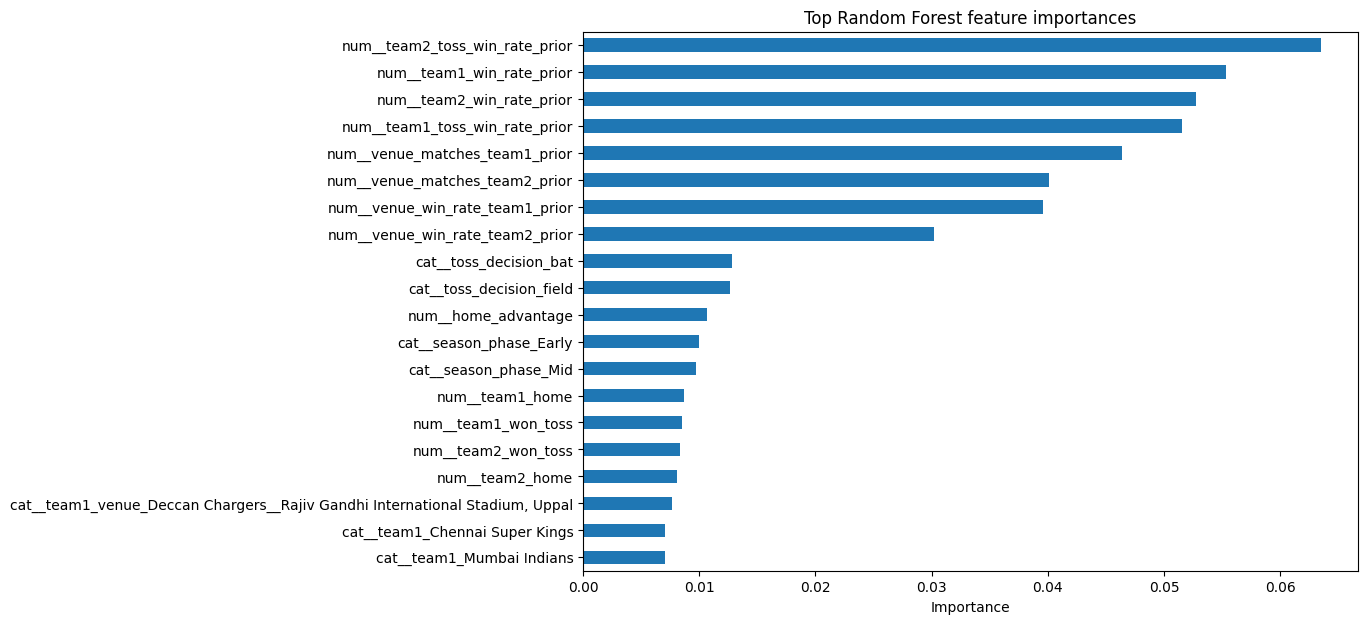

In [ ]:
# RF feature importance.
rf_names = rf.named_steps["pre"].get_feature_names_out()
rf_imp = pd.Series(rf.named_steps["model"].feature_importances_, index=rf_names).sort_values(ascending=False).head(20)
plt.figure(figsize=(10,7))
rf_imp.sort_values().plot(kind="barh")
plt.title("Top Random Forest feature importances")
plt.xlabel("Importance");

In [ ]:
# Confidence analysis for the best probability model.
best_name = comparison.iloc[0]["Model"]
best_prob = models[best_name][1]
confidence = np.maximum(best_prob, 1-best_prob)
print("Average prediction confidence:", round(confidence.mean(),4))
print("High-confidence predictions (>=0.80):", round((confidence>=0.80).mean()*100,2), "%")

Average prediction confidence: 0.6596
High-confidence predictions (>=0.80): 10.09 %


# Final findings and business interpretation

### Key methodological findings
1. **Historical/pre-match feature construction is essential.** Using the final match winner to build a feature would leak the target.
2. **Toss advantage is measurable but should not be treated as deterministic.** The descriptive toss-winner win percentage is reported above.
3. **Team clusters summarize style/performance rather than permanent team quality.** Franchise names and team composition change across IPL seasons.
4. **Trend slopes are descriptive forecasts.** A linear extrapolation cannot capture auctions, injuries, coaching changes or rule changes.
5. **KNN PoM prediction is limited by the dataset.** The file has no player-level batting/bowling statistics, so context-only similarity cannot compete with a model using ball-by-ball player performance.
6. **Toss recommendations are historical decision heuristics.** Weather is synthetic because the supplied dataset contains no weather observations.
7. **For match prediction, chronological validation is preferred to random splitting.** The ensemble can improve probability stability, but the held-out metrics above should determine whether it actually improves over the individual models.

### Assumptions
- Historical franchise aliases were normalized for Delhi, Punjab, RCB and the two Rising Pune spellings.
- Home advantage uses an explicit city-to-franchise mapping and is therefore approximate.
- No-result/tie-like matches without a winner are excluded from winner-target models.
- Missing PoM rows are excluded from PoM modeling.
- Synthetic weather is a reproducible placeholder, not real weather data.
- Correlations in the trend analysis are associations, not causal effects.